# 05 · Integración de clientes, EDA multifuente y codificación exploratoria

**Proyecto:** Interconnect Customer Churn Prediction · TripleTen · Sprint 19  
**Etapas:** M5 (integración), M6 (EDA integrado y clustering exploratorio), preparación para M7  
**Estado:** código preparado; **sin ejecución con los CSV originales en esta sesión**.

## Objetivo y criterios de aceptación

Conservar **una fila por cliente** al integrar `contract`, `personal`, `internet` y `phone`; auditar nulos estructurales; contrastar insights históricos; crear `Churn`; construir una **matriz 100 % numérica** para EDA y clustering sin usar el target como entrada; exportar una versión original y otra codificada exploratoria.

**Criterios:** identificadores únicos, uniones 1:1, población contractual conservada, ausencia de categorías desconocidas silenciosas, control de fuga de información y trazabilidad de columnas transformadas.

**Referencias del handoff (no recalculadas):** 7.043 clientes, 1.869 cancelaciones, 5.517 registros de internet y 6.361 de telefonía. Deben confirmarse con los CSV originales.

**Advertencia predictiva:** el `OneHotEncoder` de este notebook se ajusta al dataset completo **exclusivamente para EDA exploratorio**. En el próximo notebook de entrenamiento, el codificador y el escalado se ajustarán **solo en train** (dentro de un `Pipeline`); no se entrenarán/evaluarán modelos usando directamente la codificación global exportada.

## 1 · Fuentes y supuestos

- Fuente de verdad para la población: `contract.csv`.
- Relación entre archivos: un registro como máximo por `customerID` en cada tabla; comprobar antes de unir.
- `internet.csv` y `phone.csv` son fuentes de servicios opcionales: una ausencia de fila **puede** expresar que el servicio no se contrató, y se tratará como ausencia estructural solamente si el esquema y la integridad de claves son coherentes.
- `personal.csv` debería cubrir los clientes contractuales. Un faltante aquí es una anomalía, no una categoría.
- `EndDate` se usa **solo** para crear `Churn`: `No` equivale a cliente no cancelado, una fecha válida equivale a cancelación. El instante de predicción y el horizonte aún no están definidos.
- Se conserva el contenido original en memoria. El destino preparado se guardará en `data/processed/`.

**Riesgo metodológico:** un EDA retrospectivo puede identificar asociaciones con la cancelación, pero no establece causalidad ni disponibilidad temporal de predictores. `EndDate`, duraciones calculadas al cierre y variables creadas con información posterior a la cancelación quedan fuera de ML.

### 1.1 · Importaciones y rutas

Ejecutar desde `notebooks/` o desde la raíz del repositorio. No se requiere SQL ni bases de datos externas.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 35)
pd.set_option("display.max_rows", 35)
plt.rcParams.update({
    "figure.figsize": (8, 4.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "font.size": 10,
})

ARCHIVOS = {
    "contract": "contract.csv",
    "personal": "personal.csv",
    "internet": "internet.csv",
    "phone": "phone.csv",
}

candidatos = [Path.cwd(), *Path.cwd().parents]
raiz = next(
    (p for p in candidatos if (p / "data" / "raw").is_dir()),
    None,
)
if raiz is None:
    raise FileNotFoundError(
        "No se encuentra data/raw/. Ejecuta desde la raíz del repositorio o notebooks/."
    )

raw_dir = raiz / "data" / "raw"
processed_dir = raiz / "data" / "processed"
faltan = [nombre for nombre in ARCHIVOS.values() if not (raw_dir / nombre).is_file()]
if faltan:
    raise FileNotFoundError(f"Archivos necesarios ausentes de data/raw/: {faltan}")
print("Directorio de proyecto:", raiz)
print("Datos originales:", raw_dir)

Directorio de proyecto: E:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction
Datos originales: E:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction\data\raw


### 1.2 · Carga reproducible

Se conserva `customerID` como texto, para no perder su estructura. Las tablas originales se guardan en un diccionario; los cambios se realizan sobre copias.

In [2]:
tablas_raw = {
    nombre: pd.read_csv(raw_dir / archivo, dtype={"customerID": "string"})
    for nombre, archivo in ARCHIVOS.items()
}

inventario = pd.DataFrame([
    {"fuente": nombre, "filas": len(df), "columnas": df.shape[1],
     "ids_unicos": df["customerID"].nunique(dropna=True)}
    for nombre, df in tablas_raw.items()
]).set_index("fuente")
display(inventario)

# Comparación informativa con lo documentado en notebooks anteriores
esperados_handoff = {"contract": 7043, "internet": 5517, "phone": 6361}
for fuente, esperado in esperados_handoff.items():
    observado = len(tablas_raw[fuente])
    if observado != esperado:
        print(f"REVISAR {fuente}: handoff={esperado}, archivo={observado}")

,filas,columnas,ids_unicos
fuente,,,
contract,7043,8,7043
personal,7043,5,7043
internet,5517,8,5517
phone,6361,2,6361


## 2 · Auditoría de identificadores y estructura

No corregir automáticamente duplicados: podrían multiplicar filas durante el `merge`. Si hay una inconsistencia, detener y resolverla sobre las fuentes antes de continuar.

In [3]:
tablas = {}
for nombre, origen in tablas_raw.items():
    df = origen.copy()
    df.columns = df.columns.str.strip()

    if "customerID" not in df.columns:
        raise KeyError(f"{nombre}: falta customerID")
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].astype("string").str.strip()

    if df.columns.duplicated().any():
        raise ValueError(f"{nombre}: nombres de columnas duplicados")
    if df["customerID"].isna().any() or df["customerID"].eq("").any():
        raise ValueError(f"{nombre}: customerID vacío o nulo")
    if df["customerID"].duplicated().any():
        raise ValueError(f"{nombre}: customerID duplicado")
    tablas[nombre] = df

ids_base = set(tablas["contract"]["customerID"])
filas_auditoria = []
for nombre, df in tablas.items():
    ids = set(df["customerID"])
    huerfanos = ids - ids_base
    filas_auditoria.append({
        "fuente": nombre,
        "registros": len(df),
        "ids_fuera_de_contract": len(huerfanos),
        "clientes_contract_sin_fila": len(ids_base - ids),
        "nulos_celdas_originales": int(df.isna().sum().sum()),
    })

cobertura = pd.DataFrame(filas_auditoria).set_index("fuente")
display(cobertura)

if (cobertura["ids_fuera_de_contract"] > 0).any():
    raise ValueError("Hay customerID de fuentes auxiliares ausentes de contract.")
if cobertura.loc["personal", "clientes_contract_sin_fila"]:
    raise ValueError("personal.csv no cubre a todos los clientes de contract.csv.")

# Los nombres de atributos no pueden solaparse entre fuentes (salvo la clave).
columnas_ajenas = set(tablas["contract"].columns) - {"customerID"}
for fuente in ("personal", "internet", "phone"):
    actuales = set(tablas[fuente].columns) - {"customerID"}
    if columnas_ajenas & actuales:
        raise ValueError(f"Columnas superpuestas al integrar {fuente}: {columnas_ajenas & actuales}")
    columnas_ajenas |= actuales
print("Auditoría de claves: OK")

,registros,ids_fuera_de_contract,clientes_contract_sin_fila,nulos_celdas_originales
fuente,,,,
contract,7043,0,0,0
personal,7043,0,0,0
internet,5517,0,1526,0
phone,6361,0,682,0


Auditoría de claves: OK


### 2.1 · Cobertura conjunta de internet y telefonía (ANTES del merge)

**Pregunta de integridad:** ¿la unión de los `customerID` de `internet.csv` y `phone.csv` coincide con los clientes registrados en `contract.csv`?

No basta con sumar 5.517 + 6.361: algunos clientes están en **ambas** fuentes. Aplicamos inclusión-exclusión y construimos cuatro conjuntos mutuamente excluyentes: **solo internet**, **solo teléfono**, **ambos** y **ninguno**.

Si la unión cubre los 7.043 clientes del handoff, los valores esperados (condicionales, no confirmados) son: 682 solo internet, 1.526 solo teléfono, 4.835 ambos y 0 ninguno. La comparación debe hacerse con IDs reales, no solo con tamaños.

- `ninguno == 0`: todos los clientes tienen al menos uno de los dos servicios; la ausencia de fila de un servicio es compatible con una **ausencia estructural**.
- `ninguno > 0`: inspeccionar dichos IDs y las reglas de negocio **antes de clasificar las dos ausencias como servicios no contratados**. El notebook interrumpirá posteriormente el relleno automático.
- IDs duplicados o fuera de contratos ya provocan error en la auditoría anterior.

In [4]:
ids_internet = set(tablas["internet"]["customerID"])
ids_telefono = set(tablas["phone"]["customerID"])

ids_ambos = ids_internet & ids_telefono
ids_solo_internet = ids_internet - ids_telefono
ids_solo_telefono = ids_telefono - ids_internet
ids_ninguno = ids_base - (ids_internet | ids_telefono)
ids_union = ids_internet | ids_telefono

cobertura_servicios = pd.DataFrame({
    "grupo": ["Solo internet", "Solo teléfono", "Ambos servicios", "Ninguno"],
    "clientes": [
        len(ids_solo_internet), len(ids_solo_telefono),
        len(ids_ambos), len(ids_ninguno),
    ],
})
cobertura_servicios["porcentaje"] = (
    100 * cobertura_servicios["clientes"] / len(ids_base)
).round(2)
display(cobertura_servicios)

assert sum(cobertura_servicios["clientes"]) == len(ids_base)
assert len(ids_union) == len(ids_internet) + len(ids_telefono) - len(ids_ambos)
assert ids_union.issubset(ids_base)

print(f"Clientes de contrato: {len(ids_base):,}")
print(f"Unión internet ∪ teléfono: {len(ids_union):,}")
print(f"Intersección internet ∩ teléfono: {len(ids_ambos):,}")
print(f"Clientes sin ninguno de esos registros: {len(ids_ninguno):,}")

if ids_ninguno:
    print("ALERTA: existen clientes sin registro en ninguna fuente de servicios.")
    display(
        tablas["contract"].loc[
            tablas["contract"]["customerID"].isin(ids_ninguno), ["customerID"]
        ].head(10)
    )
else:
    print("OK: todos los clientes figuran en internet, telefonía o ambos.")

,grupo,clientes,porcentaje
0,Solo internet,682,9.68
1,Solo teléfono,1526,21.67
2,Ambos servicios,4835,68.65
3,Ninguno,0,0.00


Clientes de contrato: 7,043
Unión internet ∪ teléfono: 7,043
Intersección internet ∩ teléfono: 4,835
Clientes sin ninguno de esos registros: 0
OK: todos los clientes figuran en internet, telefonía o ambos.


## 3 · Integración con LEFT JOIN

Orden: `contract` → `personal` → `internet` → `phone`. `validate='one_to_one'` verifica cardinalidad y `indicator` documenta el origen de cada registro. Se comprueba que no cambien los IDs ni el número de filas.

In [5]:
df_integrado = tablas["contract"].copy()
ids_contrato = df_integrado["customerID"].tolist()

for fuente in ("personal", "internet", "phone"):
    df_integrado = df_integrado.merge(
        tablas[fuente],
        on="customerID",
        how="left",
        validate="one_to_one",
        indicator=f"_merge_{fuente}",
        sort=False,
    )
    if len(df_integrado) != len(ids_contrato):
        raise AssertionError(f"El merge con {fuente} alteró las filas.")

assert df_integrado["customerID"].is_unique
assert df_integrado["customerID"].tolist() == ids_contrato

for fuente in ("personal", "internet", "phone"):
    print(f"Cobertura de {fuente}:")
    display(df_integrado[f"_merge_{fuente}"].value_counts().rename("clientes").to_frame())

print("Dimensiones integradas:", df_integrado.shape)
display(df_integrado.head(3))

Cobertura de personal:


,clientes
_merge_personal,
both,7043
left_only,0
right_only,0


Cobertura de internet:


,clientes
_merge_internet,
both,5517
left_only,1526
right_only,0


Cobertura de phone:


,clientes
_merge_phone,
both,6361
left_only,682
right_only,0


Dimensiones integradas: (7043, 23)


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,_merge_personal,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,_merge_internet,MultipleLines,_merge_phone
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,Female,0,Yes,No,both,DSL,No,Yes,No,No,No,No,both,<NA>,left_only
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5,Male,0,No,No,both,DSL,Yes,No,Yes,No,No,No,both,No,both
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,Male,0,No,No,both,DSL,Yes,Yes,No,No,No,No,both,No,both


### 3.1 · Ausencia estructural ≠ nulo de calidad

**Decisión condicionada a la cobertura conjunta anterior:** si todos los `customerID` de `contract` figuran en al menos uno de los servicios, se puede representar la ausencia de fila de internet o telefonía como *servicio no contratado*, siempre que las reglas de negocio confirmen que estas fuentes son completas.

- Sin internet: `InternetService = "No"` y los seis complementos = `"No internet service"`. Esta última categoría no es lo mismo que rechazar un complemento teniendo internet (`"No"`).
- Sin telefonía: `MultipleLines = "No phone service"`, que es distinto de tener una sola línea (`"No"`).
- Si existe algún cliente en **ninguna** fuente, detener el tratamiento estructural hasta investigar los identificadores; no inventar servicios.
- Un nulo dentro de una fila registrada representa un posible **problema de calidad** y no se imputa automáticamente.

Se conservan `TieneInternet` y `TieneTelefono` como indicadores explícitos para la ingeniería de características.

In [6]:
# El tratamiento estructural requiere revisar primero la cobertura de fuentes.
if ids_ninguno:
    raise ValueError(
        f"{len(ids_ninguno)} clientes no aparecen en internet ni phone. "
        "Revisar las fuentes y la política de servicios antes de rellenar sus nulos."
    )

df_integrado["TieneInternet"] = df_integrado["_merge_internet"].eq("both")
df_integrado["TieneTelefono"] = df_integrado["_merge_phone"].eq("both")

cols_internet = [c for c in tablas["internet"].columns if c != "customerID"]
cols_phone = [c for c in tablas["phone"].columns if c != "customerID"]
servicios_extra = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]
necesarias_internet = {"InternetService", *servicios_extra}
if not necesarias_internet.issubset(cols_internet):
    raise KeyError(f"Columnas de internet ausentes: {necesarias_internet - set(cols_internet)}")
if "MultipleLines" not in cols_phone:
    raise KeyError("phone.csv debe contener MultipleLines")

for nombre, columnas, bandera in (
    ("internet", cols_internet, "TieneInternet"),
    ("phone", cols_phone, "TieneTelefono"),
):
    nulos_reales = df_integrado.loc[df_integrado[bandera], columnas].isna().sum()
    if nulos_reales.any():
        raise ValueError(
            f"{nombre}: nulos dentro de registros presentes:\n{nulos_reales[nulos_reales > 0]}"
        )

faltante_internet = ~df_integrado["TieneInternet"]
faltante_phone = ~df_integrado["TieneTelefono"]

# Etiquetas semánticamente distintas para servicio ausente y complemento rechazado.
df_integrado.loc[faltante_internet, cols_internet] = "No internet service"
df_integrado.loc[faltante_internet, "InternetService"] = "No"
df_integrado.loc[faltante_phone, "MultipleLines"] = "No phone service"

for columna in servicios_extra:
    categorias = set(df_integrado[columna].dropna().unique().tolist())
    if not categorias.issubset({"Yes", "No", "No internet service"}):
        raise ValueError(f"Valores inesperados en {columna}: {categorias}")

assert df_integrado.loc[faltante_internet, servicios_extra].eq(
    "No internet service"
).all().all()
assert df_integrado.loc[~faltante_internet, servicios_extra].ne(
    "No internet service"
).all().all()

if not set(df_integrado["MultipleLines"].dropna().unique()).issubset(
    {"Yes", "No", "No phone service"}
):
    raise ValueError("MultipleLines tiene categorías inesperadas.")

assert df_integrado["TieneInternet"].sum() == len(ids_internet)
assert df_integrado["TieneTelefono"].sum() == len(ids_telefono)

# Los indicadores de merge se retiran al haber verificado su contenido.
df_integrado = df_integrado.drop(
    columns=[f"_merge_{fuente}" for fuente in ("personal", "internet", "phone")]
)

print("Clientes sin internet:", int(faltante_internet.sum()))
print("Clientes sin telefonía:", int(faltante_phone.sum()))
display(
    df_integrado.isna().sum().loc[lambda s: s > 0]
        .sort_values(ascending=False).to_frame("nulos")
)

Clientes sin internet: 1526
Clientes sin telefonía: 682


,nulos


## 4 · Variable objetivo y datos temporales

`Churn` se construye a partir de `EndDate`, pero solo después de validar que sus valores son `No` o fechas válidas. Se conserva `EndDate` en la **tabla analítica** para trazabilidad; se excluye de la tabla candidata para ML. Este target es una **cancelación histórica observada**: antes de afirmar predicción futura habría que fijar fecha de corte, ventana de observación y horizonte.

In [7]:
if not {"BeginDate", "EndDate"}.issubset(df_integrado.columns):
    raise KeyError("Faltan BeginDate o EndDate en contract.csv")

end_texto = df_integrado["EndDate"].astype("string").str.strip()
if end_texto.isna().any() or end_texto.eq("").any():
    raise ValueError("Hay EndDate vacías; no se puede construir Churn de forma fiable.")

sigue_activo = end_texto.str.casefold().eq("no")
end_fechas = pd.to_datetime(end_texto.where(~sigue_activo), errors="coerce")
if (end_fechas.isna() & ~sigue_activo).any():
    ejemplos = end_texto[end_fechas.isna() & ~sigue_activo].unique().tolist()[:5]
    raise ValueError(f"EndDate no reconocidas como fecha ni 'No': {ejemplos}")

df_integrado["Churn"] = (~sigue_activo).astype("int8")
comienzos = pd.to_datetime(df_integrado["BeginDate"], errors="coerce")
if comienzos.isna().any():
    raise ValueError("BeginDate contiene fechas no válidas.")
if ((end_fechas < comienzos) & ~sigue_activo).any():
    raise ValueError("Se encontraron EndDate anteriores a BeginDate.")

conteos_target = df_integrado["Churn"].value_counts().sort_index()
display(pd.DataFrame({
    "clientes": conteos_target,
    "porcentaje": (conteos_target / len(df_integrado) * 100).round(2)
}).rename(index={0: "Activo / Churn=0", 1: "Cancelado / Churn=1"}))

if int(df_integrado["Churn"].sum()) != 1869:
    print("REVISAR: el número de cancelaciones difiere del handoff (1.869).")

,clientes,porcentaje
Churn,,
Activo / Churn=0,5174,73.46
Cancelado / Churn=1,1869,26.54


### 4.1 · Normalización prudente de cargos

`TotalCharges` contiene 11 cadenas compuestas por espacios según el EDA contractual. Se transforman importes válidos a tipo numérico, pero **no** se convierte automáticamente un blanco en cero. Los blancos se inspeccionan y se preservan como `NaN` para decidir posteriormente su tratamiento.

In [8]:
for columna in ("MonthlyCharges", "TotalCharges"):
    if columna not in df_integrado.columns:
        raise KeyError(f"Falta {columna} en contract.csv")
    texto = df_integrado[columna].astype("string").str.strip().replace("", pd.NA)
    numerico = pd.to_numeric(texto, errors="coerce")
    invalidos = texto.notna() & numerico.isna()
    if invalidos.any():
        raise ValueError(f"{columna}: existen valores no numéricos inesperados")
    df_integrado[columna] = numerico.astype("float64")

print("Vacíos de TotalCharges:", df_integrado["TotalCharges"].isna().sum())
print("Ejemplos para revisión de TotalCharges:")
display(
    df_integrado.loc[
        df_integrado["TotalCharges"].isna(),
        ["customerID", "BeginDate", "EndDate", "MonthlyCharges", "TotalCharges", "Churn"]
    ].head(15)
)
if df_integrado["TotalCharges"].isna().sum() != 11:
    print("REVISAR: cantidad de TotalCharges vacíos distinta del handoff (11).")

Vacíos de TotalCharges: 11
Ejemplos para revisión de TotalCharges:


,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,2020-02-01,No,52.55,NaN,0
753,3115-CZMZD,2020-02-01,No,20.25,NaN,0
936,5709-LVOEQ,2020-02-01,No,80.85,NaN,0
1082,4367-NUYAO,2020-02-01,No,25.75,NaN,0
1340,1371-DWPAZ,2020-02-01,No,56.05,NaN,0
3331,7644-OMVMY,2020-02-01,No,19.85,NaN,0
3826,3213-VVOLG,2020-02-01,No,25.35,NaN,0
4380,2520-SGTTA,2020-02-01,No,20.00,NaN,0
5218,2923-ARZLG,2020-02-01,No,19.70,NaN,0
6670,4075-WKNIU,2020-02-01,No,73.35,NaN,0


## 5 · Revisión de insights del EDA independiente

**Resultados previos que se contrastarán, no supuestos del nuevo dataset:**

1. **Contrato:** el abandono histórico fue de 42,7 % para mes a mes, 11,3 % para anual y 2,8 % para dos años. `MonthlyCharges`, `PaperlessBilling` y `PaymentMethod` mostraron asociaciones descriptivas.
2. **Internet:** DSL destacó relativamente en `OnlineSecurity`/`TechSupport`; fibra, en `StreamingTV`/`StreamingMovies`. La *composición* de servicios parecía más informativa que su cantidad.
3. **Telefonía:** `MultipleLines` tenía 53,29 % `No` y 46,71 % `Yes` **entre los 6.361 clientes de phone.csv**; esa proporción no describe por sí sola a toda la población contractual.
4. **Personal:** evaluar las variables `gender`, `SeniorCitizen`, `Partner` y `Dependents` frente a `Churn`, sin trasladar hallazgos no documentados.
5. **Clustering previo:** los perfiles exploratorios describieron segmentos, pero no se comprobó valor predictivo incremental. No se incorporarán etiquetas de clusters al modelo por ahora.

Estas comparaciones son **retrospectivas**, no pruebas causales. Prestar atención a los tamaños de muestra de cada grupo.

### 5.1 · Churn por tipo de contrato

Esta tabla y su gráfico permiten comparar los porcentajes anteriores con la tabla integrada; el denominador es la población de cada categoría.

,clientes,cancelaciones,tasa_pct
Type,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


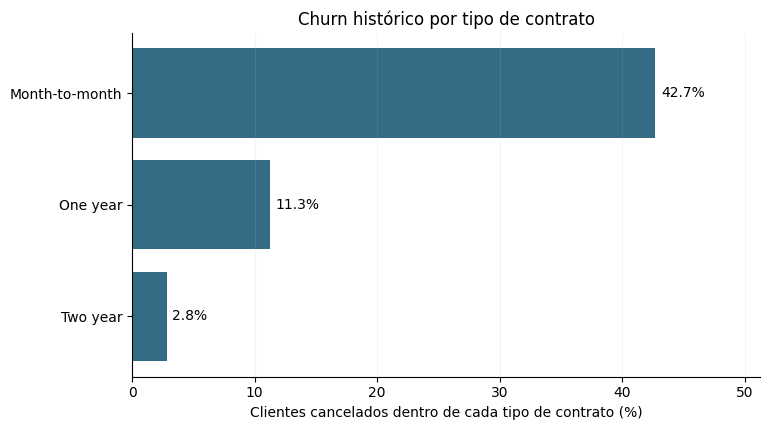

In [9]:
def resumen_churn(df, grupo):
    return (
        df.groupby(grupo, dropna=False, observed=True)["Churn"]
          .agg(clientes="size", cancelaciones="sum", tasa="mean")
          .assign(tasa_pct=lambda x: (100 * x["tasa"]).round(2))
          .drop(columns="tasa")
          .sort_values("tasa_pct", ascending=False)
    )

por_contrato = resumen_churn(df_integrado, "Type")
display(por_contrato)

fig, ax = plt.subplots(figsize=(7.8, 4.4))
valores = por_contrato["tasa_pct"].sort_values()
barras = ax.barh(valores.index.astype(str), valores.to_numpy(), color="#356C85")
ax.bar_label(barras, fmt="%.1f%%", padding=4)
ax.set_xlabel("Clientes cancelados dentro de cada tipo de contrato (%)")
ax.set_title("Churn histórico por tipo de contrato")
ax.set_xlim(0, max(8, float(valores.max()) * 1.2))
ax.grid(axis="x", alpha=0.15)
plt.tight_layout()
plt.show()

### 5.2 · Contrato × tecnología de internet

Interacción candidata: ¿se mantiene una tasa alta de abandono en contratos mes a mes *dentro de cada tecnología*? El conteo por celda evita sobrerinterpretar grupos muy pequeños.

In [10]:
for variable in ["InternetService", "TieneTelefono", "MultipleLines", "PaperlessBilling", "PaymentMethod", "SeniorCitizen", "Partner", "Dependents", "gender"]:
    if variable in df_integrado.columns:
        print(f"\n{variable}")
        display(resumen_churn(df_integrado, variable).head(12))

cruce = (
    df_integrado.groupby(["Type", "InternetService"], dropna=False, observed=True)["Churn"]
        .agg(clientes="size", tasa_pct=lambda x: round(100 * x.mean(), 2))
        .reset_index()
)
display(cruce.sort_values(["Type", "InternetService"]))


InternetService


,clientes,cancelaciones,tasa_pct
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No,1526,113,7.40



TieneTelefono


,clientes,cancelaciones,tasa_pct
TieneTelefono,,,
True,6361,1699,26.71
False,682,170,24.93



MultipleLines


...


Dependents


,clientes,cancelaciones,tasa_pct
Dependents,,,
No,4933,1543,31.28
Yes,2110,326,15.45



gender


,clientes,cancelaciones,tasa_pct
gender,,,
Female,3488,939,26.92
Male,3555,930,26.16


,Type,InternetService,clientes,tasa_pct
0,Month-to-month,DSL,1223,32.22
1,Month-to-month,Fiber optic,2128,54.61
2,Month-to-month,No,524,18.89
3,One year,DSL,570,9.30
4,One year,Fiber optic,539,19.29
5,One year,No,364,2.47
6,Two year,DSL,628,1.91
7,Two year,Fiber optic,429,7.23
8,Two year,No,638,0.78


### 5.3 · Mapa de calor de la interacción

Cada celda muestra tasa de cancelación y tamaño de grupo. Las celdas sin datos permanecen vacías (no se les asigna 0 %).

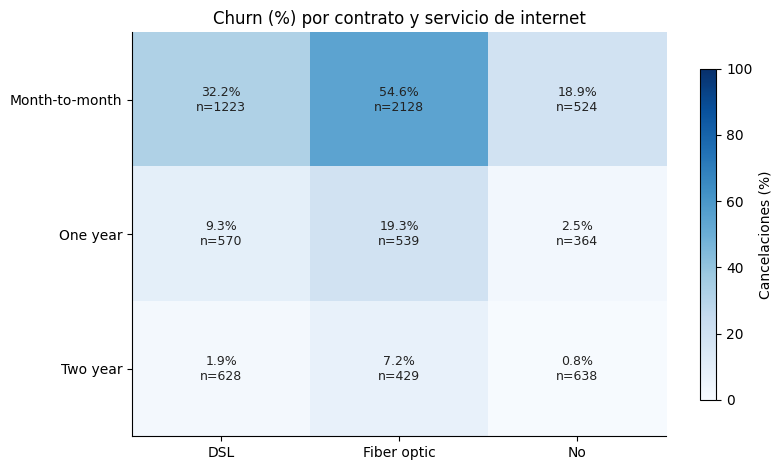

In [11]:
matriz_tasas = cruce.pivot(index="Type", columns="InternetService", values="tasa_pct")
matriz_n = cruce.pivot(index="Type", columns="InternetService", values="clientes")
fig, ax = plt.subplots(figsize=(8.2, 4.8))
datos = np.ma.masked_invalid(matriz_tasas.to_numpy(dtype=float))
im = ax.imshow(datos, cmap="Blues", aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(len(matriz_tasas.columns)), matriz_tasas.columns.astype(str))
ax.set_yticks(range(len(matriz_tasas.index)), matriz_tasas.index.astype(str))
ax.set_title("Churn (%) por contrato y servicio de internet")
for i in range(len(matriz_tasas.index)):
    for j in range(len(matriz_tasas.columns)):
        valor = matriz_tasas.iat[i, j]
        if pd.notna(valor):
            n = int(matriz_n.iat[i, j])
            color = "white" if valor > 55 else "#222222"
            ax.text(j, i, f"{valor:.1f}%\nn={n}", ha="center", va="center", color=color, fontsize=9)
fig.colorbar(im, ax=ax, label="Cancelaciones (%)", shrink=0.82)
plt.tight_layout()
plt.show()

## 6 · Ingeniería de características exploratorias

Derivaciones exclusivamente a partir del inventario de servicios:

- `NumServiciosInternet`: número de complementos activos (`Yes`) de los seis servicios de internet.
- `SeguridadYSoporte`: contratación simultánea de seguridad online y soporte técnico.
- `StreamingCompleto`: contratación simultánea de TV y películas.
- `TieneInternet`, `TieneTelefono`: indicadores de presencia de registro del servicio.

No se usa `Churn`, `EndDate`, ni duración posterior al abandono para crear ninguna de estas variables. La utilidad incremental deberá evaluarse en validación, no suponerse por el EDA.

In [12]:
df_integrado["NumServiciosInternet"] = (
    df_integrado[servicios_extra].eq("Yes").sum(axis=1).astype("int8")
)
df_integrado["SeguridadYSoporte"] = (
    df_integrado["OnlineSecurity"].eq("Yes") & df_integrado["TechSupport"].eq("Yes")
)
df_integrado["StreamingCompleto"] = (
    df_integrado["StreamingTV"].eq("Yes") & df_integrado["StreamingMovies"].eq("Yes")
)

# Coherencia: sin internet, ningún complemento activo.
assert df_integrado.loc[~df_integrado["TieneInternet"], "NumServiciosInternet"].eq(0).all()

for columna in ["NumServiciosInternet", "SeguridadYSoporte", "StreamingCompleto"]:
    print(f"\n{columna}")
    display(resumen_churn(df_integrado, columna))


NumServiciosInternet


,clientes,cancelaciones,tasa_pct
NumServiciosInternet,,,
1,966,442,45.76
2,1033,370,35.82
3,1118,306,27.37
4,852,190,22.30
0,2219,475,21.41
5,571,71,12.43
6,284,15,5.28



SeguridadYSoporte


,clientes,cancelaciones,tasa_pct
SeguridadYSoporte,,,
False,5944,1770,29.78
True,1099,99,9.01



StreamingCompleto


,clientes,cancelaciones,tasa_pct
StreamingCompleto,,,
True,1940,571,29.43
False,5103,1298,25.44


### 6.1 · Composición de servicios dentro de cada tecnología

Contrastar las observaciones del notebook 02 evitando mezclar a los clientes sin internet. Se muestran porcentajes de activación en cada tecnología, y no porcentajes sobre el conjunto de la compañía.

InternetService,DSL,Fiber optic
Servicio complementario,,
OnlineSecurity,48.7,27.1
OnlineBackup,44.9,43.4
DeviceProtection,44.0,43.8
TechSupport,48.7,28.0
StreamingTV,39.5,56.5
StreamingMovies,40.5,56.6


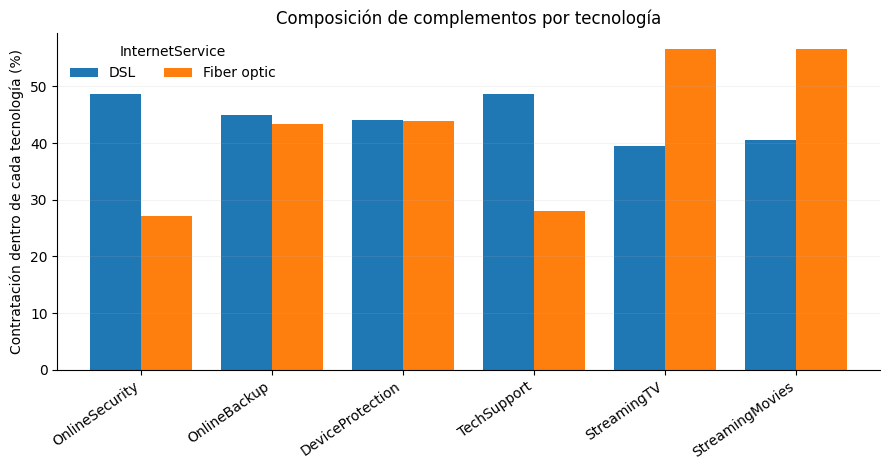

In [13]:
con_internet = df_integrado.loc[df_integrado["TieneInternet"]].copy()
uso = (
    con_internet.groupby("InternetService", observed=True)[servicios_extra]
    .agg(lambda col: round(100 * col.eq("Yes").mean(), 1))
)
display(uso.T.rename_axis("Servicio complementario"))

fig, ax = plt.subplots(figsize=(9, 4.8))
uso.T.plot(kind="bar", ax=ax, width=0.78)
ax.set_ylabel("Contratación dentro de cada tecnología (%)")
ax.set_xlabel("")
ax.set_title("Composición de complementos por tecnología")
ax.legend(title="InternetService", frameon=False, ncol=2)
ax.grid(axis="y", alpha=0.15)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### 6.2 · Auditoría relacional: cobertura, cargos y abandono

**Pregunta:** ¿cómo se distribuyen los clientes entre *solo internet*, *solo telefonía* y *ambos*, y cómo varían los cargos mensuales y la cancelación? Usamos `TieneInternet` y `TieneTelefono`, definidos a partir de las uniones verificadas.

`MonthlyCharges` es el **cargo mensual total del cliente**, no una tarifa desagregada de cada servicio. Los promedios describen asociaciones, no diferencias causales de precio.

,clientes,cargo_medio,cargo_mediano,churn_pct
PerfilServicios,,,,
Internet + teléfono,4835,81.76,82.50,32.80
Solo teléfono,1526,21.08,20.15,7.40
Solo internet,682,42.03,40.58,24.93


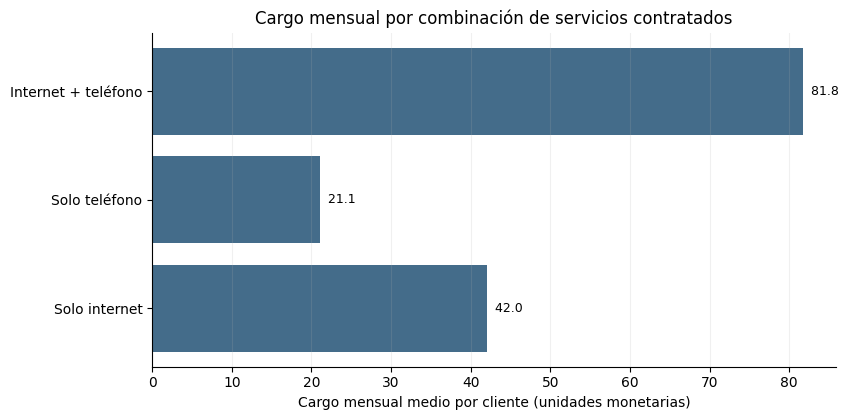

In [14]:
# Perfil exclusivo basado en la presencia de filas en cada servicio.
condiciones = [
    df_integrado["TieneInternet"] & df_integrado["TieneTelefono"],
    df_integrado["TieneInternet"] & ~df_integrado["TieneTelefono"],
    ~df_integrado["TieneInternet"] & df_integrado["TieneTelefono"],
]
etiquetas = ["Internet + teléfono", "Solo internet", "Solo teléfono"]
analisis_integrado = df_integrado.assign(
    PerfilServicios=np.select(condiciones, etiquetas, default="Ninguno")
)

perfil_servicios = (
    analisis_integrado.groupby("PerfilServicios", observed=True)
    .agg(clientes=("customerID", "size"),
         cargo_medio=("MonthlyCharges", "mean"),
         cargo_mediano=("MonthlyCharges", "median"),
         tasa_churn=("Churn", "mean"))
    .assign(churn_pct=lambda x: 100 * x["tasa_churn"])
    .drop(columns="tasa_churn")
    .round(2)
    .sort_values("clientes", ascending=False)
)
display(perfil_servicios)

assert perfil_servicios["clientes"].sum() == len(df_integrado)
assert int(df_integrado["TieneInternet"].sum()) == len(ids_internet)
assert int(df_integrado["TieneTelefono"].sum()) == len(ids_telefono)

fig, ax = plt.subplots(figsize=(8.6, 4.3))
valores = perfil_servicios["cargo_medio"]
ax.barh(valores.index, valores.values, color="#446C8A")
ax.invert_yaxis()
ax.set_xlabel("Cargo mensual medio por cliente (unidades monetarias)")
ax.set_title("Cargo mensual por combinación de servicios contratados")
ax.grid(axis="x", alpha=0.18)
for i, v in enumerate(valores.values):
    ax.text(v, i, f"  {v:.1f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

### 6.3 · Contrato × internet × telefonía: cargo mensual y Churn

Comprobamos si las diferencias históricas por tipo de contrato persisten al controlar descriptivamente por tecnología y contratación de telefonía. **El tamaño de cada grupo importa**: no interpretar tasas de celdas pequeñas como estimaciones estables.

La tabla mantiene tanto la media como la mediana del importe mensual; la variable de abandono se resume en porcentaje.

In [15]:
cruce_servicio_contrato = (
    df_integrado.groupby(["Type", "InternetService", "TieneTelefono"], observed=True)
    .agg(clientes=("customerID", "size"),
         cargo_medio=("MonthlyCharges", "mean"),
         cargo_mediano=("MonthlyCharges", "median"),
         churn_pct=("Churn", lambda serie: 100 * serie.mean()))
    .reset_index()
    .round({"cargo_medio": 2, "cargo_mediano": 2, "churn_pct": 2})
)
print("Todas las combinaciones observadas:", len(cruce_servicio_contrato))
print("Grupos con al menos 30 clientes (umbral descriptivo):")
display(
    cruce_servicio_contrato.loc[cruce_servicio_contrato["clientes"] >= 30]
    .sort_values(["Type", "InternetService", "TieneTelefono"])
)
print("Grupos pequeños (<30), revisar antes de interpretar:",
      int(cruce_servicio_contrato["clientes"].lt(30).sum()))

Todas las combinaciones observadas: 12
Grupos con al menos 30 clientes (umbral descriptivo):


,Type,InternetService,TieneTelefono,clientes,cargo_medio,cargo_mediano,churn_pct
0,Month-to-month,DSL,False,376,36.82,35.10,40.69
1,Month-to-month,DSL,True,847,56.17,54.70,28.45
2,Month-to-month,Fiber optic,True,2128,87.02,86.00,54.61
3,Month-to-month,No,True,524,20.41,20.05,18.89
4,One year,DSL,False,145,45.04,44.45,9.66
5,One year,DSL,True,425,66.98,66.50,9.18
6,One year,Fiber optic,True,539,98.78,100.15,19.29
7,One year,No,True,364,20.82,20.10,2.47
8,Two year,DSL,False,161,51.48,53.10,1.86
9,Two year,DSL,True,467,77.01,79.40,1.93


Grupos pequeños (<30), revisar antes de interpretar: 0


### 6.4 · Modalidad de pago × contrato × facturación electrónica

**Preguntas:** ¿qué formas de pago y contratos predominan en los clientes que cancelan? ¿Cómo cambian los cargos mensuales dentro de esas combinaciones? No interpretar `PaymentMethod` como una causa del abandono; pueden intervenir antigüedad, tecnología u otras diferencias de composición.

La tabla está ordenada por número de clientes y filtra grupos con muy pocas observaciones para facilitar la lectura.

,Type,PaymentMethod,PaperlessBilling,clientes,cargo_medio,cargo_mediano,churn_pct
5,Month-to-month,Electronic check,Yes,1397,77.69,81.00,57.70
6,Month-to-month,Mailed check,No,469,38.65,25.20,25.16
4,Month-to-month,Electronic check,No,453,66.67,71.35,41.50
7,Month-to-month,Mailed check,Yes,424,54.23,54.12,38.68
1,Month-to-month,Bank transfer (automatic),Yes,383,74.89,79.75,38.12
3,Month-to-month,Credit card (automatic),Yes,382,72.79,78.22,34.82
18,Two year,Credit card (automatic),No,305,54.21,51.35,1.97
17,Two year,Bank transfer (automatic),Yes,288,75.76,82.60,4.51
19,Two year,Credit card (automatic),Yes,276,75.71,82.95,2.54
16,Two year,Bank transfer (automatic),No,276,53.80,54.40,2.17


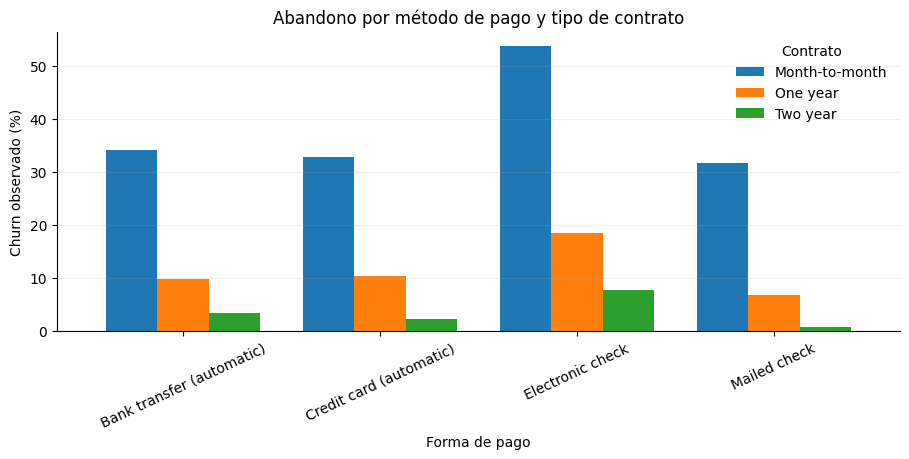

Nota: los denominadores de cada barra están en 'pago_contrato'.


,PaymentMethod,Type,clientes,churn_pct
0,Bank transfer (automatic),Month-to-month,589,34.125637
1,Bank transfer (automatic),One year,391,9.718670
2,Bank transfer (automatic),Two year,564,3.368794
3,Credit card (automatic),Month-to-month,543,32.780847
4,Credit card (automatic),One year,398,10.301508
5,Credit card (automatic),Two year,581,2.237522
6,Electronic check,Month-to-month,1850,53.729730
7,Electronic check,One year,347,18.443804
8,Electronic check,Two year,168,7.738095
9,Mailed check,Month-to-month,893,31.578947


In [16]:
cruce_pago = (
    df_integrado.groupby(["Type", "PaymentMethod", "PaperlessBilling"], observed=True)
    .agg(clientes=("customerID", "size"),
         cargo_medio=("MonthlyCharges", "mean"),
         cargo_mediano=("MonthlyCharges", "median"),
         churn_pct=("Churn", lambda serie: 100 * serie.mean()))
    .reset_index()
    .round({"cargo_medio": 2, "cargo_mediano": 2, "churn_pct": 2})
)
display(
    cruce_pago.loc[cruce_pago["clientes"] >= 30]
    .sort_values("clientes", ascending=False)
    .head(25)
)

# Comparación visual: tasa de abandono por método de pago y tipo contractual.
pago_contrato = (
    df_integrado.groupby(["PaymentMethod", "Type"], observed=True)
    .agg(clientes=("customerID", "size"),
         churn_pct=("Churn", lambda x: x.mean() * 100))
    .reset_index()
)
matriz_pago = pago_contrato.pivot(
    index="PaymentMethod", columns="Type", values="churn_pct"
)
ax = matriz_pago.plot(kind="bar", figsize=(9.2, 4.7), width=0.78)
ax.set_title("Abandono por método de pago y tipo de contrato")
ax.set_ylabel("Churn observado (%)")
ax.set_xlabel("Forma de pago")
ax.set_ylim(bottom=0)
ax.legend(title="Contrato", frameon=False)
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.18)
plt.tight_layout()
plt.show()
print("Nota: los denominadores de cada barra están en 'pago_contrato'.")
display(pago_contrato.sort_values(["PaymentMethod", "Type"]))

### 6.5 · Complementos de internet × tecnología × cargo mensual

Comparamos, **solo entre quienes tienen internet**, el número de servicios adicionales (`NumServiciosInternet`) con su cargo mensual y churn. Así distinguimos cantidad de complementos y tecnología de conexión, sin mezclar clientes que no tienen servicio.

El resultado es descriptivo. Un precio total superior entre quienes contratan complementos no equivale al precio unitario de cada complemento.

,InternetService,NumServiciosInternet,clientes,cargo_medio,cargo_mediano,churn_pct
0,DSL,0,294,40.28,44.75,41.16
1,DSL,1,415,46.49,50.00,32.29
2,DSL,2,454,52.09,55.15,20.26
3,DSL,3,475,59.31,62.85,13.05
4,DSL,4,359,67.86,71.00,9.19
5,DSL,5,281,75.60,79.90,5.34
6,DSL,6,143,84.63,88.70,1.40
7,Fiber optic,0,399,72.08,70.75,60.40
8,Fiber optic,1,551,79.95,80.00,55.90
9,Fiber optic,2,579,88.35,89.15,48.01


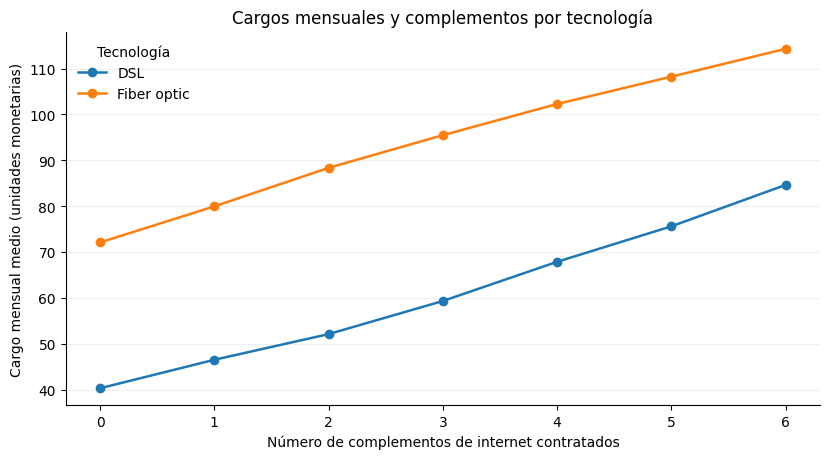

Total con internet auditado: 5517


In [17]:
internet_complementos = (
    df_integrado.loc[df_integrado["TieneInternet"]]
    .groupby(["InternetService", "NumServiciosInternet"], observed=True)
    .agg(clientes=("customerID", "size"),
         cargo_medio=("MonthlyCharges", "mean"),
         cargo_mediano=("MonthlyCharges", "median"),
         churn_pct=("Churn", lambda x: x.mean() * 100))
    .reset_index()
    .round({"cargo_medio": 2, "cargo_mediano": 2, "churn_pct": 2})
)
display(internet_complementos)

fig, ax = plt.subplots(figsize=(8.4, 4.7))
for tecnologia, grupo in internet_complementos.groupby("InternetService", observed=True):
    grupo = grupo.sort_values("NumServiciosInternet")
    ax.plot(grupo["NumServiciosInternet"], grupo["cargo_medio"],
            marker="o", linewidth=1.8, label=tecnologia)
ax.set_xlabel("Número de complementos de internet contratados")
ax.set_ylabel("Cargo mensual medio (unidades monetarias)")
ax.set_title("Cargos mensuales y complementos por tecnología")
ax.legend(title="Tecnología", frameon=False)
ax.grid(axis="y", alpha=0.18)
plt.tight_layout()
plt.show()

print("Total con internet auditado:", len(df_integrado.loc[df_integrado["TieneInternet"]]))
assert int(internet_complementos["clientes"].sum()) == int(df_integrado["TieneInternet"].sum())

### 6.6 · Combinaciones concretas de servicios y modalidades comerciales

Para descubrir patrones **multivariables**, agrupamos por tecnología, presencia de telefonía, múltiples líneas, tipo de contrato y forma de pago. Las combinaciones exactas son numerosas: mostramos únicamente las que tienen 40 clientes o más y conservamos el conteo como denominador. Estas tablas sirven para formular hipótesis de ingeniería de características, **no para seleccionar variables a partir de test**.

Los análisis posteriores deberán confirmar si una interacción mejora AUC-ROC y Recall respecto de usar sus componentes por separado.

In [18]:
segmentos = (
    df_integrado.groupby(
        ["InternetService", "TieneTelefono", "MultipleLines", "Type", "PaymentMethod"],
        observed=True
    )
    .agg(clientes=("customerID", "size"),
         cargo_medio=("MonthlyCharges", "mean"),
         churn_pct=("Churn", lambda x: 100 * x.mean()))
    .reset_index()
    .round({"cargo_medio": 2, "churn_pct": 2})
)
segmentos_interpretables = segmentos.loc[segmentos["clientes"] >= 40]
print("Combinaciones distintas:", len(segmentos),
      "| con al menos 40 clientes:", len(segmentos_interpretables))
display(segmentos_interpretables.sort_values("clientes", ascending=False).head(20))

# Integridad de la agrupación: cada cliente aparece en una combinación.
assert int(segmentos["clientes"].sum()) == len(df_integrado)

Combinaciones distintas: 84 | con al menos 40 clientes: 56


,InternetService,TieneTelefono,MultipleLines,Type,PaymentMethod,clientes,cargo_medio,churn_pct
50,Fiber optic,True,Yes,Month-to-month,Electronic check,742,91.28,60.92
38,Fiber optic,True,No,Month-to-month,Electronic check,565,81.80,59.65
63,No,True,No,Month-to-month,Mailed check,303,19.97,21.45
15,DSL,True,No,Month-to-month,Mailed check,222,52.85,31.08
14,DSL,True,No,Month-to-month,Electronic check,218,54.19,37.61
48,Fiber optic,True,Yes,Month-to-month,Bank transfer (automatic),211,91.95,45.02
49,Fiber optic,True,Yes,Month-to-month,Credit card (automatic),182,91.11,42.86
71,No,True,No,Two year,Mailed check,180,19.94,0.56
2,DSL,False,No phone service,Month-to-month,Electronic check,175,37.74,49.71
67,No,True,No,One year,Mailed check,148,19.93,1.35


## 7 · Codificación numérica explícita para el análisis exploratorio

Objetivo: producir `X_numerica` usando **exactamente las 21 características candidatas** (sin `Churn`), con variables binarias codificadas a `0/1`, tres variables nominales mediante `OneHotEncoder`, y dos numéricas sin alterar. 

- **Binarias directas:** `PaperlessBilling`, `gender`, `Partner`, `Dependents` → mapeo validado; `SeniorCitizen`, `TieneInternet`, `TieneTelefono`, `SeguridadYSoporte`, `StreamingCompleto` → conversión verificada a `0/1`.
- **Servicios (`Yes`, `No`, ausencia estructural):** los seis complementos y `MultipleLines` se expresan como `Yes → 1` y demás valores válidos → `0`. Se conserva la diferencia entre **No** y **sin servicio** mediante `InternetService_No` / `TieneInternet` y `TieneTelefono`.
- **Multiclase nominales:** `Type`, `PaymentMethod`, `InternetService` → `OneHotEncoder` **sin `drop`**; cada categoría observada tiene indicador propio.
- **Numéricas:** `MonthlyCharges`, `NumServiciosInternet` permanecen numéricas. El escalado, cuando sea necesario, se hace aparte, no se sobrescriben los importes.

**Punto metodológico:** `gender` se codifica binariamente porque en estas fuentes se esperan dos etiquetas; `0/1` **no** representa orden, jerarquía ni diferencias causales. Se detendrá la ejecución ante etiquetas nuevas para auditar su significado. `OneHotEncoder` aquí aprende el *vocabulario* completo para descripción; **no reemplaza el ajuste en train que exige ML supervisado**.

### 7.1 · Matriz candidata y auditoría de categorías

In [19]:
from sklearn.preprocessing import OneHotEncoder

columnas_excluidas = ["customerID", "EndDate", "BeginDate", "TotalCharges"]
df_modelado_base = df_integrado.drop(columns=columnas_excluidas).copy()
X_candidatas = df_modelado_base.drop(columns="Churn")
y = df_modelado_base["Churn"].astype("int8")

COLUMNAS_OHE = ["Type", "PaymentMethod", "InternetService"]
COLUMNAS_BINARIAS_YN = ["PaperlessBilling", "Partner", "Dependents"]
COLUMNAS_BINARIAS_SERVICIO = [*servicios_extra, "MultipleLines"]
COLUMNAS_BINARIAS_EXISTENTES = [
    "SeniorCitizen", "TieneInternet", "TieneTelefono",
    "SeguridadYSoporte", "StreamingCompleto",
]
COLUMNAS_NUMERICAS = ["MonthlyCharges", "NumServiciosInternet"]

columnas_esperadas = (
    COLUMNAS_OHE + COLUMNAS_BINARIAS_YN + ["gender"]
    + COLUMNAS_BINARIAS_SERVICIO + COLUMNAS_BINARIAS_EXISTENTES
    + COLUMNAS_NUMERICAS
)
assert len(columnas_esperadas) == 21 and len(set(columnas_esperadas)) == 21
if set(X_candidatas.columns) != set(columnas_esperadas):
    raise ValueError(
        f"Columnas distintas a las 21 esperadas. "
        f"Faltantes: {set(columnas_esperadas)-set(X_candidatas.columns)}; "
        f"extras: {set(X_candidatas.columns)-set(columnas_esperadas)}"
    )
if X_candidatas.isna().any().any():
    raise ValueError(f"Existen nulos antes de codificar: {X_candidatas.isna().sum().loc[lambda s: s>0]}")

print("Matriz candidata original:", X_candidatas.shape)
print("Target:", y.name, "| positivos:", int(y.sum()))
print("Nº de categorías en columnas multiclase:")
for nombre in COLUMNAS_OHE:
    print(f"  {nombre}: {sorted(X_candidatas[nombre].astype(str).unique().tolist())}")
display(X_candidatas.dtypes.astype(str).rename("tipo_original").to_frame())
assert set(y.unique().tolist()) == {0, 1}


Matriz candidata original: (7043, 21)
Target: Churn | positivos: 1869
Nº de categorías en columnas multiclase:
  Type: ['Month-to-month', 'One year', 'Two year']
  PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
  InternetService: ['DSL', 'Fiber optic', 'No']


,tipo_original
Type,string
PaperlessBilling,string
PaymentMethod,string
MonthlyCharges,float64
gender,string
SeniorCitizen,int64
Partner,string
Dependents,string
InternetService,string
OnlineSecurity,string


### 7.2 · Binarización controlada y One-Hot Encoding

In [20]:
# No modificar la tabla integrada: conserva las etiquetas para interpretación.
X_binarias = pd.DataFrame(index=X_candidatas.index)

def mapa_binario(serie, mapa, nombre):
    encontrados = set(serie.dropna().astype(str).unique())
    desconocidos = encontrados - set(mapa)
    if desconocidos:
        raise ValueError(f"{nombre}: categorías no contempladas: {sorted(desconocidos)}")
    resultado = serie.astype(str).map(mapa)
    if resultado.isna().any():
        raise ValueError(f"{nombre}: faltantes al convertir a 0/1")
    return resultado.astype("int8")

for nombre in COLUMNAS_BINARIAS_YN:
    X_binarias[nombre] = mapa_binario(X_candidatas[nombre], {"Yes":1, "No":0}, nombre)
X_binarias["gender"] = mapa_binario(
    X_candidatas["gender"], {"Female":0, "Male":1}, "gender"
)
for nombre in COLUMNAS_BINARIAS_SERVICIO:
    permitido = {"Yes":1, "No":0,
        "No internet service":0, "No phone service":0}
    X_binarias[nombre] = mapa_binario(X_candidatas[nombre], permitido, nombre)

for nombre in COLUMNAS_BINARIAS_EXISTENTES:
    encontrados = set(X_candidatas[nombre].dropna().astype(int).unique().tolist())
    if not encontrados.issubset({0,1}):
        raise ValueError(f"{nombre}: valores distintos de 0/1: {encontrados}")
    X_binarias[nombre] = X_candidatas[nombre].astype("int8")

# Codificación de categorías nominales. Sin eliminar ninguna categoría de referencia.
# Válido para EDA; NO reutilizar este objeto ajustado para un experimento supervisado.
ohe_eda = OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                        dtype=np.int8, drop=None)
ohe_array = ohe_eda.fit_transform(X_candidatas[COLUMNAS_OHE])
nombres_ohe = ohe_eda.get_feature_names_out(COLUMNAS_OHE).tolist()
X_onehot = pd.DataFrame(ohe_array, columns=nombres_ohe, index=X_candidatas.index)

# Evitar sobrescribir o duplicar columnas y mantener tipos numéricos claros.
X_numerica = pd.concat([
    X_binarias,
    X_candidatas[COLUMNAS_NUMERICAS].astype({
        "MonthlyCharges":"float64", "NumServiciosInternet":"int8"}),
    X_onehot,
], axis=1)

if X_numerica.columns.duplicated().any():
    raise ValueError("Nombres de columnas repetidos tras la codificación")
if X_numerica.isna().any().any():
    raise ValueError("La codificación introdujo nulos")
if not all(pd.api.types.is_numeric_dtype(dt) for dt in X_numerica.dtypes):
    raise TypeError("Quedan características no numéricas")
if not np.isfinite(X_numerica.to_numpy(dtype=float)).all():
    raise ValueError("La matriz contiene infinitos o valores no finitos")

assert len(X_numerica) == len(y) == len(tablas["contract"])
assert X_numerica.index.equals(y.index)
for i, nombre in enumerate(COLUMNAS_OHE):
    cols = [f"{nombre}_{cat}" for cat in ohe_eda.categories_[i]]
    assert X_numerica[cols].sum(axis=1).eq(1).all(), f"One-Hot no exclusivo: {nombre}"
for columna in columnas_excluidas + ["Churn", "Cluster"]:
    assert columna not in X_numerica.columns

print("Matriz totalmente numérica (para EDA):", X_numerica.shape)
print("Binarias:", X_binarias.shape[1], "| Numéricas:", len(COLUMNAS_NUMERICAS),
      "| One-Hot:", len(nombres_ohe))
display(X_numerica.dtypes.astype(str).rename("tipo_numerico").to_frame())
display(X_numerica.head(3))


Matriz totalmente numérica (para EDA): (7043, 28)
Binarias: 16 | Numéricas: 2 | One-Hot: 10


,tipo_numerico
PaperlessBilling,int8
Partner,int8
Dependents,int8
gender,int8
OnlineSecurity,int8
OnlineBackup,int8
DeviceProtection,int8
TechSupport,int8
StreamingTV,int8
StreamingMovies,int8


,PaperlessBilling,Partner,Dependents,gender,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines,SeniorCitizen,TieneInternet,TieneTelefono,SeguridadYSoporte,StreamingCompleto,MonthlyCharges,NumServiciosInternet,Type_Month-to-month,Type_One year,Type_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,1,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,29.85,1,1,0,0,0,0,1,0,1,0,0
1,0,0,0,1,1,0,1,0,0,0,0,0,1,1,0,0,56.95,2,0,1,0,0,0,0,1,1,0,0
2,1,0,0,1,1,1,0,0,0,0,0,0,1,1,0,0,53.85,2,1,0,0,0,0,0,1,1,0,0


### 7.3 · Diccionario de características y controles de significado

El diccionario enlaza columnas numéricas y fuentes. La matriz codificada es **una vista para análisis**; la interpretación de negocio debe continuar consultando `df_integrado`, con etiquetas legibles.

Comprobamos especialmente que un `0` de complemento en clientes sin internet no implique que rechazaron el servicio: su disponibilidad sigue registrada por la tecnología y la bandera `TieneInternet`.

In [21]:
diccionario_caracteristicas = []
for nombre in X_numerica.columns:
    if nombre in nombres_ohe:
        origen = next(base for base in COLUMNAS_OHE if nombre.startswith(base + "_"))
        metodo = "OneHotEncoder (EDA, fit global)"
        definicion = f"1 si {origen} = {nombre[len(origen)+1:]}; 0 en otro caso"
    elif nombre in COLUMNAS_NUMERICAS:
        origen, metodo, definicion = nombre, "Numérica", "Valor original sin escalado"
    elif nombre in COLUMNAS_BINARIAS_SERVICIO:
        origen, metodo = nombre, "Binaria servicio"
        definicion = "1=Yes; 0=No o servicio no contratado (ver banderas)"
    elif nombre == "gender":
        origen, metodo, definicion = nombre, "Binaria nominal", "Female=0, Male=1 (sin orden)"
    elif nombre in COLUMNAS_BINARIAS_YN:
        origen, metodo, definicion = nombre, "Binaria Yes/No", "Yes=1, No=0"
    else:
        origen, metodo, definicion = nombre, "Binaria existente", "1=Sí/verdadero; 0=No/falso"
    diccionario_caracteristicas.append({
        "feature": nombre, "variable_origen": origen,
        "transformacion": metodo, "interpretacion": definicion,
    })
df_diccionario = pd.DataFrame(diccionario_caracteristicas)
assert len(df_diccionario) == X_numerica.shape[1]
assert X_numerica["TieneInternet"].eq(0).equals(
    X_numerica["InternetService_No"].eq(1))
assert X_numerica.loc[X_numerica["TieneInternet"].eq(0),
    servicios_extra].eq(0).all().all()
assert X_numerica["NumServiciosInternet"].equals(
    X_numerica[servicios_extra].sum(axis=1).astype("int8"))
print("Diccionario de columnas numéricas:")
display(df_diccionario)


Diccionario de columnas numéricas:


,feature,variable_origen,transformacion,interpretacion
0,PaperlessBilling,PaperlessBilling,Binaria Yes/No,"Yes=1, No=0"
1,Partner,Partner,Binaria Yes/No,"Yes=1, No=0"
2,Dependents,Dependents,Binaria Yes/No,"Yes=1, No=0"
3,gender,gender,Binaria nominal,"Female=0, Male=1 (sin orden)"
4,OnlineSecurity,OnlineSecurity,Binaria servicio,1=Yes; 0=No o servicio no contratado (ver band...
5,OnlineBackup,OnlineBackup,Binaria servicio,1=Yes; 0=No o servicio no contratado (ver band...
6,DeviceProtection,DeviceProtection,Binaria servicio,1=Yes; 0=No o servicio no contratado (ver band...
7,TechSupport,TechSupport,Binaria servicio,1=Yes; 0=No o servicio no contratado (ver band...
8,StreamingTV,StreamingTV,Binaria servicio,1=Yes; 0=No o servicio no contratado (ver band...
9,StreamingMovies,StreamingMovies,Binaria servicio,1=Yes; 0=No o servicio no contratado (ver band...


## 8 · Clustering multifuente sobre las características numéricas

**Hipótesis exploratoria:** determinados perfiles comerciales pueden presentar tasas históricas de Churn significativamente distintas. **Churn no interviene en K-Means ni en la selección de k**.

Ahora utilizamos `X_numerica` (creada en el paso 7): las categorías nominales están en One-Hot, las binarias en 0/1 y solo se estandariza `MonthlyCharges` para la métrica de distancia. Se excluyen atributos demográficos, contadores derivados y representaciones duplicadas (`TieneInternet`, etc.) del **espacio de clustering**; siguen disponibles para interpretar los grupos.

**Limitación:** la distancia euclidiana no es una medida perfecta para mezclar indicadores y precio. Clusters descriptivos **no equivalen** a grupos predictivos ni prueban causalidad. El resultado puede diferir de experimentos anteriores por cambio de representación y variables.


### 8.1 · Selección transparente de variables numéricas para agrupar

Se reutilizan los mismos valores codificados para toda la investigación; el dataset original con texto permanece disponible para describir las categorías de cada grupo. Las columnas añadidas por OHE tienen prefijos `Type_`, `PaymentMethod_` e `InternetService_`.

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Un atributo por concepto comercial; evitar duplicados obvios y target.
columnas_cluster_binarias = [
    "PaperlessBilling", "MultipleLines", *servicios_extra,
]
columnas_cluster_ohe = nombres_ohe
columnas_cluster = columnas_cluster_binarias + columnas_cluster_ohe + ["MonthlyCharges"]
assert set(columnas_cluster).issubset(X_numerica.columns)
assert "Churn" not in columnas_cluster

X_cluster_eda = X_numerica[columnas_cluster].copy()
X_cluster_eda["MonthlyCharges"] = StandardScaler().fit_transform(
    X_cluster_eda[["MonthlyCharges"]]).ravel()
X_cluster = X_cluster_eda.to_numpy(dtype=np.float64)
assert X_cluster.shape[0] == len(df_integrado)
assert np.isfinite(X_cluster).all()

print("Clientes:", X_cluster.shape[0])
print("Variables de clustering numéricas:", X_cluster.shape[1])
print("Espacio de clustering:", columnas_cluster)
print("Churn excluido: OK")


Clientes: 7043
Variables de clustering numéricas: 19
Espacio de clustering: ['PaperlessBilling', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Type_Month-to-month', 'Type_One year', 'Type_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'MonthlyCharges']
Churn excluido: OK


### 8.2 · Elección de k sin mirar el abandono

Se compara el coeficiente de silueta (mayor indica mejor separación relativa) y el tamaño del menor cluster. Como control descriptivo, preferimos soluciones donde **cada grupo contenga al menos un 3 % de la población o 100 clientes, lo que sea mayor**. Si ninguna satisface el mínimo, se informa y se usa la mejor silueta disponible sin ocultarlo.

La solución de seis clusters del EDA 01 sirve como **referente metodológico**, no como garantía de repetición de resultados: ahora las variables y la distancia son diferentes.

,k,silhouette_muestra,grupo_menor,grupo_mayor,cumple_minimo
0,2,0.242,2931,4112,True
1,3,0.238,1576,3097,True
2,4,0.223,1515,2149,True
3,5,0.212,1125,1845,True
4,6,0.192,924,1528,True


k elegido = 2; mínimo descriptivo buscado = 212 clientes


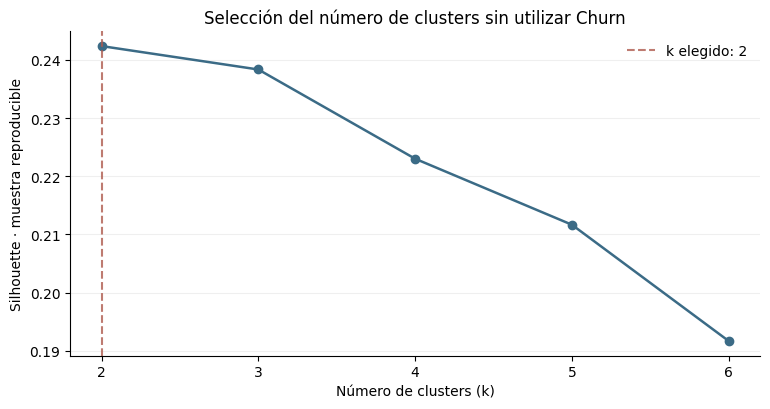

In [23]:
SEMILLA_CLUSTER = 42
K_CANDIDATOS = list(range(2, 7))
MIN_CLIENTES = max(100, int(np.ceil(len(df_integrado) * 0.03)))

registros_k = []
modelos_k = {}
for k in K_CANDIDATOS:
    modelo = KMeans(n_clusters=k, random_state=SEMILLA_CLUSTER, n_init=10)
    etiquetas = modelo.fit_predict(X_cluster)
    tamanos = pd.Series(etiquetas).value_counts()
    silueta = silhouette_score(
        X_cluster, etiquetas,
        sample_size=min(1200, len(df_integrado)),
        random_state=SEMILLA_CLUSTER,
    )
    registros_k.append({
        "k": k, "silhouette_muestra": silueta,
        "grupo_menor": int(tamanos.min()), "grupo_mayor": int(tamanos.max()),
        "cumple_minimo": bool(tamanos.min() >= MIN_CLIENTES),
    })
    modelos_k[k] = modelo

comparacion_k = pd.DataFrame(registros_k)
display(comparacion_k.round(3))

candidatos_validos = comparacion_k.loc[comparacion_k["cumple_minimo"]]
if candidatos_validos.empty:
    print("ATENCIÓN: ningún k satisface el mínimo de clientes; se prioriza la silueta.")
    candidatos_validos = comparacion_k

K_ELEGIDO = int(candidatos_validos.sort_values(
    ["silhouette_muestra", "k"], ascending=[False, True]
).iloc[0]["k"])
print(f"k elegido = {K_ELEGIDO}; mínimo descriptivo buscado = {MIN_CLIENTES} clientes")

fig, ax = plt.subplots(figsize=(7.8, 4.2))
ax.plot(comparacion_k["k"], comparacion_k["silhouette_muestra"],
        marker="o", linewidth=1.8, color="#3B6B86")
ax.axvline(K_ELEGIDO, color="#AE5A4E", linestyle="--", alpha=.8,
           label=f"k elegido: {K_ELEGIDO}")
ax.set_xticks(K_CANDIDATOS)
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Silhouette · muestra reproducible")
ax.set_title("Selección del número de clusters sin utilizar Churn")
ax.grid(axis="y", alpha=.2)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 8.3 · ¿Dónde se concentra el abandono?

Solo **después** de seleccionar `k` añadimos `Cluster` a una **copia exploratoria**. Calculamos dos medidas distintas:

- **Tasa de abandono del cluster**: cancelaciones / clientes de ese cluster. Identifica el riesgo histórico *relativo*.
- **Porcentaje de todas las cancelaciones**: cancelaciones del cluster / todas las cancelaciones. Identifica su peso sobre el problema total.

La línea discontinua del gráfico es la tasa global observada. Esta comparación describe asociación; no mide rendimiento fuera de muestra ni demuestra predicción o causalidad.

Tasa general de Churn = 26.54%
Índice Churn = 1 significa tasa igual a la media del conjunto


,clientes,cancelaciones,cargo_medio,cargo_mediano,tasa_churn_pct,indice_churn,peso_clientes_pct,parte_cancelaciones_pct
Cluster,,,,,,,,
1,2931,486,33.73,25.25,16.58,0.62,41.62,26.0
0,4112,1383,86.88,86.00,33.63,1.27,58.38,74.0


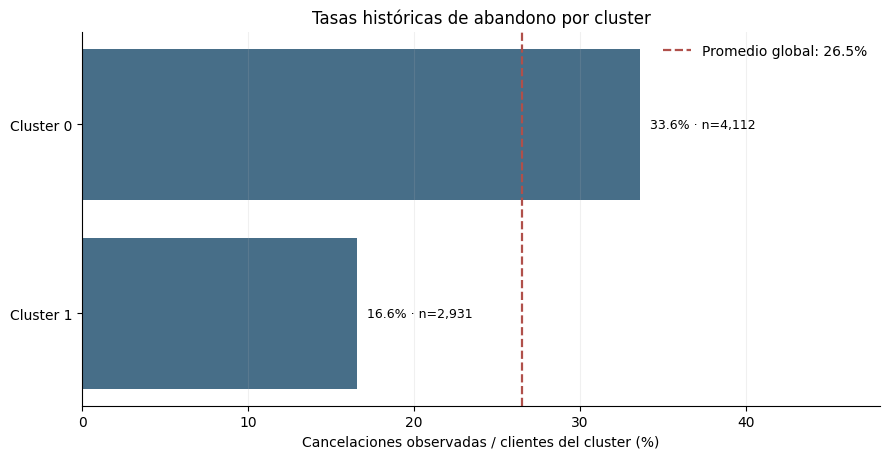

In [24]:
df_clusters = df_integrado.copy()
df_clusters["Cluster"] = modelos_k[K_ELEGIDO].labels_.astype(int)

tasa_global = df_clusters["Churn"].mean()
tabla_clusters = (
    df_clusters.groupby("Cluster", observed=True)
    .agg(
        clientes=("customerID", "size"),
        cancelaciones=("Churn", "sum"),
        cargo_medio=("MonthlyCharges", "mean"),
        cargo_mediano=("MonthlyCharges", "median"),
    )
)
tabla_clusters["tasa_churn_pct"] = 100 * tabla_clusters["cancelaciones"] / tabla_clusters["clientes"]
tabla_clusters["indice_churn"] = tabla_clusters["tasa_churn_pct"] / (100 * tasa_global)
tabla_clusters["peso_clientes_pct"] = 100 * tabla_clusters["clientes"] / len(df_clusters)
tabla_clusters["parte_cancelaciones_pct"] = (
    100 * tabla_clusters["cancelaciones"] / df_clusters["Churn"].sum()
)
tabla_clusters = tabla_clusters.sort_values("tasa_churn_pct")

assert tabla_clusters["clientes"].sum() == len(df_integrado)
assert tabla_clusters["cancelaciones"].sum() == df_integrado["Churn"].sum()
assert df_clusters["customerID"].is_unique

print(f"Tasa general de Churn = {100*tasa_global:.2f}%")
print("Índice Churn = 1 significa tasa igual a la media del conjunto")
display(tabla_clusters.round(2))

fig, ax = plt.subplots(figsize=(9, 4.7))
barras = ax.barh([f"Cluster {i}" for i in tabla_clusters.index],
                tabla_clusters["tasa_churn_pct"], color="#476E88")
ax.axvline(100*tasa_global, color="#B0504A", linestyle="--", linewidth=1.6,
           label=f"Promedio global: {100*tasa_global:.1f}%")
for bar, (_, row) in zip(barras, tabla_clusters.iterrows()):
    ax.text(bar.get_width()+0.6, bar.get_y()+bar.get_height()/2,
            f"{row['tasa_churn_pct']:.1f}% · n={int(row['clientes']):,}",
            va="center", fontsize=9)
ax.set_xlim(0, max(100*tasa_global, tabla_clusters["tasa_churn_pct"].max())*1.43)
ax.set_xlabel("Cancelaciones observadas / clientes del cluster (%)")
ax.set_title("Tasas históricas de abandono por cluster")
ax.grid(axis="x", alpha=.18)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 8.4 · ¿Cómo son los clusters con menor y mayor tasa de abandono?

Comparamos sus proporciones categóricas con las de la población general; una diferencia positiva en puntos porcentuales significa que esa categoría aparece más frecuentemente en ese segmento. Se perfilan también atributos personales **que no intervinieron en el algoritmo**, útiles como descripción adicional. Las diferencias no prueban relaciones causales.

**Precaución:** si un grupo tiene muy pocos clientes, su tasa de Churn y su perfil serán inestables. Consultar siempre los tamaños de la tabla anterior.

In [25]:
CLUSTER_BAJO = int(tabla_clusters.index[0])
CLUSTER_ALTO = int(tabla_clusters.index[-1])

variables_perfil = ["Type", "PaymentMethod", "PaperlessBilling", "InternetService", "MultipleLines", *servicios_extra] + [
    col for col in ("Partner", "Dependents", "SeniorCitizen", "gender")
    if col in df_clusters.columns
]

def describir_cluster(numero_cluster, max_filas=12):
    """Categorías sobrerrepresentadas respecto de toda la clientela."""
    es_segmento = df_clusters["Cluster"].eq(numero_cluster)
    filas = []
    for variable in variables_perfil:
        serie = df_clusters[variable].astype("string").fillna("Sin información")
        porcentajes_generales = serie.value_counts(normalize=True, dropna=False) * 100
        porcentajes_segmento = serie.loc[es_segmento].value_counts(normalize=True, dropna=False) * 100
        for categoria, base_pct in porcentajes_generales.items():
            pct = float(porcentajes_segmento.get(categoria, 0))
            filas.append({
                "variable": variable, "categoria": str(categoria),
                "pct_en_cluster": pct, "pct_global": float(base_pct),
                "diferencia_pp": pct - float(base_pct),
            })
    perfil = pd.DataFrame(filas)
    # Se destacan categorías relativamente frecuentes, evitando modas muy raras.
    perfil = perfil.loc[perfil["pct_en_cluster"] >= 10]
    return perfil.sort_values("diferencia_pp", ascending=False).head(max_filas).round(1)

for nombre, cluster_id in (("MENOR tasa de abandono", CLUSTER_BAJO),
                           ("MAYOR tasa de abandono", CLUSTER_ALTO)):
    registro = tabla_clusters.loc[cluster_id]
    print(f"\n{nombre}: Cluster {cluster_id} | "
          f"{int(registro['clientes']):,} clientes | "
          f"{registro['tasa_churn_pct']:.1f}% Churn | "
          f"{int(registro['cancelaciones'])} cancelaciones | "
          f"cargo mediano: {registro['cargo_mediano']:.2f}")
    display(describir_cluster(cluster_id))

# Cruce explícito del volumen: cada columna es el número de clientes de un grupo.
tabla_abandono_clusters = pd.crosstab(
    df_clusters["Cluster"], df_clusters["Churn"]
).rename(columns={0:"Sin cancelación", 1:"Con cancelación"})
print("Recuento absoluto de los dos estados por grupo:")
display(tabla_abandono_clusters)


MENOR tasa de abandono: Cluster 1 | 2,931 clientes | 16.6% Churn | 486 cancelaciones | cargo mediano: 25.25


,variable,categoria,pct_en_cluster,pct_global,diferencia_pp
32,StreamingMovies,No internet service,52.1,21.7,30.4
23,DeviceProtection,No internet service,52.1,21.7,30.4
20,OnlineBackup,No internet service,52.1,21.7,30.4
17,OnlineSecurity,No internet service,52.1,21.7,30.4
11,InternetService,No,52.1,21.7,30.4
26,TechSupport,No internet service,52.1,21.7,30.4
29,StreamingTV,No internet service,52.1,21.7,30.4
8,PaperlessBilling,No,60.4,40.8,19.6
4,PaymentMethod,Mailed check,41.8,22.9,18.9
12,MultipleLines,No,64.8,48.1,16.6



MAYOR tasa de abandono: Cluster 0 | 4,112 clientes | 33.6% Churn | 1383 cancelaciones | cargo mediano: 86.00


,variable,categoria,pct_en_cluster,pct_global,diferencia_pp
9,InternetService,Fiber optic,75.0,44.0,31.0
28,StreamingTV,Yes,60.9,38.4,22.5
31,StreamingMovies,Yes,61.1,38.8,22.3
13,MultipleLines,Yes,60.0,42.2,17.8
22,DeviceProtection,Yes,50.7,34.4,16.3
7,PaperlessBilling,Yes,73.2,59.2,14.0
19,OnlineBackup,Yes,48.4,34.5,13.9
15,OnlineSecurity,No,63.4,49.7,13.8
24,TechSupport,No,60.9,49.3,11.6
3,PaymentMethod,Electronic check,44.6,33.6,11.0


Recuento absoluto de los dos estados por grupo:


Churn,Sin cancelación,Con cancelación
Cluster,,
0,2729,1383
1,2445,486


### 8.5 · Vista bidimensional: estructura de clusters frente a Churn

Para observar **hasta dónde** el abandono coincide con la estructura descubierta, proyectamos las variables transformadas a dos componentes principales (*PCA*). La imagen es una proyección: superposiciones aquí no descartan diferencias en el espacio completo y una separación visual no valida capacidad predictiva.

Los dos paneles muestran **los mismos puntos**, coloreados respectivamente por cluster y por el Churn histórico que **no se usó en K-Means**.

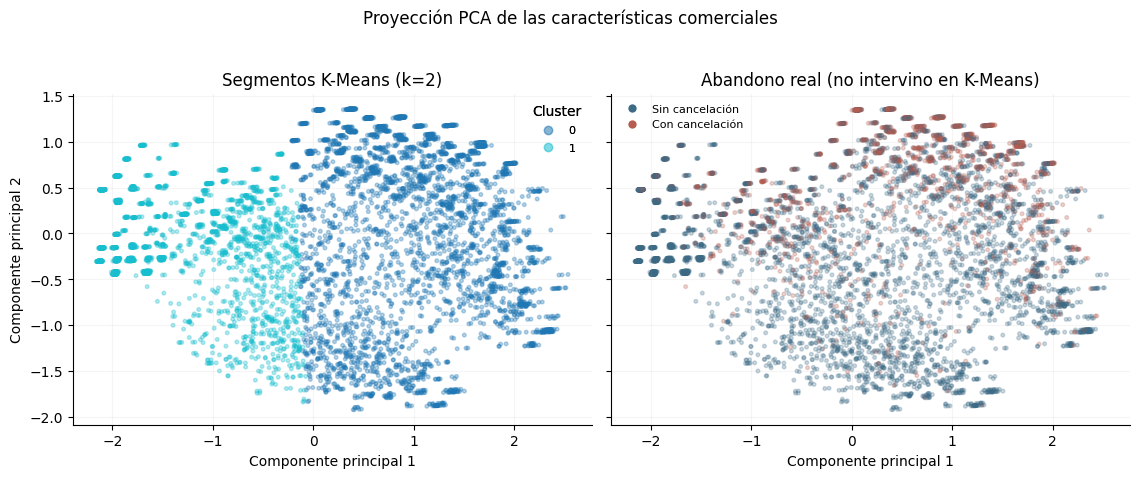

Varianza explicada por ambos componentes: 49.9%


In [26]:
from sklearn.decomposition import PCA

pca_2d = PCA(n_components=2, random_state=SEMILLA_CLUSTER)
coordenadas = pca_2d.fit_transform(X_cluster)
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharex=True, sharey=True)

sc = ejes[0].scatter(coordenadas[:, 0], coordenadas[:, 1],
                     c=df_clusters["Cluster"].to_numpy(), cmap="tab10",
                     s=7, alpha=.32, rasterized=True)
ejes[0].set_title(f"Segmentos K-Means (k={K_ELEGIDO})")
leyenda_clusters = ejes[0].legend(*sc.legend_elements(), title="Cluster",
                                  loc="best", frameon=False, fontsize=8)
ejes[0].add_artist(leyenda_clusters)

colores_estado = np.where(df_clusters["Churn"].to_numpy() == 1, "#B65C50", "#3D6B86")
ejes[1].scatter(coordenadas[:, 0], coordenadas[:, 1],
                c=colores_estado, s=7, alpha=.26, rasterized=True)
ejes[1].set_title("Abandono real (no intervino en K-Means)")
from matplotlib.lines import Line2D
leyenda = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c,
                  markersize=7, label=nombre) for c, nombre in
           [("#3D6B86", "Sin cancelación"), ("#B65C50", "Con cancelación")]]
ejes[1].legend(handles=leyenda, frameon=False, fontsize=8)
for ax in ejes:
    ax.set_xlabel("Componente principal 1")
    ax.grid(alpha=.12)
ejes[0].set_ylabel("Componente principal 2")
plt.suptitle("Proyección PCA de las características comerciales", y=1.03)
plt.tight_layout()
plt.show()
print("Varianza explicada por ambos componentes: "
      f"{pca_2d.explained_variance_ratio_.sum():.1%}")

### 8.6 · Cierre del experimento de segmentación

Después de ejecutar **con los CSV reales**, registrar las respuestas usando las tablas y gráficos anteriores:

1. ¿Qué `k` se seleccionó y cuál es la silueta aproximada? ¿Todos los grupos son suficientemente grandes?
2. ¿Qué clusters tienen las tasas más baja y más alta? Informar **tasa, cancelaciones y clientes**, no solo porcentajes.
3. ¿El grupo de mayor tasa concentra muchas cancelaciones o representa pocos clientes?
4. ¿Qué contratos, precios, métodos de pago, tecnologías y complementos están sobrerrepresentados en ambos grupos extremos?
5. ¿Qué diferencias aparecen frente al clustering de contratos del notebook 01? **No equiparar números de cluster entre métodos**.

**Límite:** encontrar segmentos de bajo o alto Churn en un análisis retrospectivo **no implica** que sean estables en el futuro, ni que K-Means mejore AUC-ROC. Si posteriormente queremos usar la etiqueta `Cluster` como característica de un clasificador, debemos ajustar **codificación, escalado y K-Means solo sobre train**, y asignar los grupos de validación/test sin reajustar. Por ahora, `df_clusters` se mantiene separado de la matriz candidata de ML; no se exporta `Cluster` como predictor.

## 9 · Tablas candidatas y exportación

El dataset tiene **dos representaciones diferentes**, ambas sin las columnas temporalmente problemáticas (`EndDate`, `BeginDate`, `TotalCharges`) y sin el identificador:

1. `clientes_modelado_base.csv`: características **originales** + `Churn`; es el punto de partida apropiado para `train/validation/test` y pipelines supervisados en el siguiente notebook.
2. `clientes_codificados_eda.csv`: características **100 % numéricas** + `Churn` con One-Hot ajustado sobre **toda la población**, válida para **exploración/visualización y experimentos descriptivos**, **no para evaluación supervisada fuera de muestra**.

Se exportan también `clientes_integrados.csv` (auditoría de negocio; incluye fechas e importes acumulados) y `diccionario_features_05.csv` (trazabilidad). El dataset exploratorio numérico **no incluye las etiquetas de clusters**.

In [27]:
assert df_integrado["customerID"].is_unique
assert set(df_integrado["customerID"]) == ids_base
assert len(df_integrado) == len(tablas["contract"])
assert int(y.sum()) == int(df_integrado["Churn"].sum())
assert not any(c in X_numerica for c in columnas_excluidas + ["Churn", "Cluster"])
assert len(X_numerica) == len(y)
assert X_numerica.index.equals(y.index)

# Churn únicamente como etiqueta, nunca como predictor.
df_modelado_numerico_eda = X_numerica.assign(Churn=y)
assert df_modelado_numerico_eda.shape[1] == X_numerica.shape[1] + 1
assert df_modelado_base.shape[1] == 22

processed_dir.mkdir(parents=True, exist_ok=True)
salidas = {
    "clientes_integrados.csv": df_integrado,
    "clientes_modelado_base.csv": df_modelado_base,
    "clientes_codificados_eda.csv": df_modelado_numerico_eda,
    "diccionario_features_05.csv": df_diccionario,
}
for nombre, frame in salidas.items():
    destino = processed_dir / nombre
    frame.to_csv(destino, index=False, encoding="utf-8")
    print(f"Guardado: {destino} | {frame.shape}")

print(f"Churn global: {100*y.mean():.2f}% | cancelaciones: {int(y.sum()):,}")
print("Archivo codificado: EXCLUSIVO PARA EDA. Reajustar OneHotEncoder en train para ML.")


Guardado: E:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction\data\processed\clientes_integrados.csv | (7043, 26)
Guardado: E:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction\data\processed\clientes_modelado_base.csv | (7043, 22)
Guardado: E:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction\data\processed\clientes_codificados_eda.csv | (7043, 29)
Guardado: E:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction\data\processed\diccionario_features_05.csv | (28, 4)
Churn global: 26.54% | cancelaciones: 1,869
Archivo codificado: EXCLUSIVO PARA EDA. Reajustar OneHotEncoder en train para ML.


## 10 · Cierre del EDA y traspaso al entrenamiento

Completar después de la **ejecución con archivos reales**:

1. Confirmar cobertura y `LEFT JOIN` uno a uno: 7.043 clientes esperados, ausencia o presencia de registros opcionales y nulos estructurales correctamente interpretados.
2. Confirmar target y patrones: 1.869 cancelaciones esperadas; revisar los cruces de contrato, precio, forma de pago, tecnología, complementos y datos personales.
3. Examinar grupos K-Means sin Churn como predictor: silueta, distribución de tamaños, tasas extremas, cancelaciones absolutas y perfil de contratación. Comparar con el clustering contractual del notebook 01 sin asumir equivalencia de segmentos.
4. Confirmar la matriz de **21 columnas originales** y el número efectivo de columnas numéricas tras One-Hot según las categorías observadas. Las variables `0/1` no necesitan One-Hot adicional.
5. En notebook 06: definir horizonte/fecha de predicción, particiones estratificadas (train/validation/test), `ColumnTransformer` y `Pipeline` con `OneHotEncoder` y `StandardScaler` **ajustados en train**; después entrenar regresión logística baseline sin balanceo y un modelo alternativo. AUC-ROC principal, Recall adicional; reservar test hasta selección final.

**Límites:** análisis retrospectivo ≠ predicción prospectiva. Nunca introducir `EndDate`, permanencia final ni `TotalCharges` postevento como variables predictivas. Las conclusiones reales quedan pendientes hasta ejecutar los CSV originales.